# Análisis exploratorio · AI4I 2020 Predictive Maintenance

**Objetivo:** entender los datos antes de entrenar el modelo de fallos del nodo de Mantenimiento.
Cada hallazgo de este notebook se traduce en una decisión del entrenamiento (`ml/train.py`).

Dataset: *AI4I 2020 Predictive Maintenance Dataset* (UCI Machine Learning Repository, CC BY 4.0).

In [17]:
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("../datasets/ai4i2020.csv")

FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]
FAILURE_MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]
TARGET = "Machine failure"

print(f"lightgbm {lightgbm.__version__} · shap {shap.__version__} · pandas {pd.__version__}")
df.head()

lightgbm 4.7.0 · shap 0.54.1 · pandas 3.1.1


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 1. Visión general

¿Cuántas filas y columnas hay? ¿De qué tipo es cada una? ¿Hay nulos o duplicados?

In [18]:
print(f"Filas: {df.shape[0]} · Columnas: {df.shape[1]}")
print(f"Nulos: {df.isna().sum().sum()} · Filas duplicadas: {df.duplicated().sum()}")
print(f"Product ID únicos: {df['Product ID'].nunique()}")
df.info()

Filas: 10000 · Columnas: 14
Nulos: 0 · Filas duplicadas: 0
Product ID únicos: 10000
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF 

In [19]:
df[FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.0,108.0,162.0,253.0


> **Conclusión:** 10.000 filas y 14 columnas, sin valores nulos ni filas duplicadas: el dataset
> está limpio. `UDI` y `Product ID` son **identificadores**: no describen el estado físico de la
> máquina, así que no entrarán en el modelo.

## 2. Desequilibrio de clases

¿Qué proporción de filas son fallo?

,filas,proporción
Machine failure,,
0,9661,0.9661
1,339,0.0339


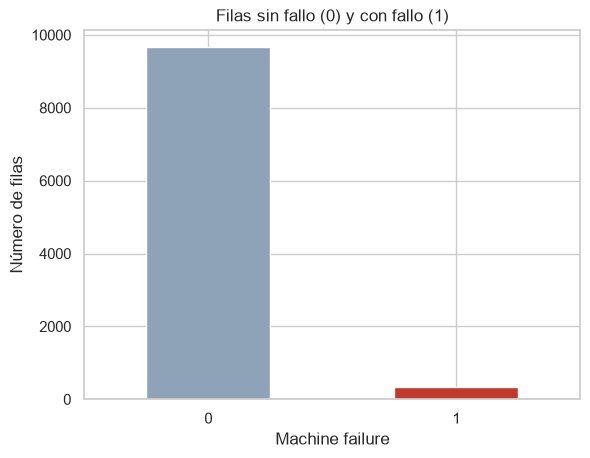

In [20]:
counts = df[TARGET].value_counts()
proportions = df[TARGET].value_counts(normalize=True)
display(pd.DataFrame({"filas": counts, "proporción": proportions.round(4)}))

ax = counts.plot.bar(rot=0, color=["#8fa3b8", "#c0392b"])
ax.set_title("Filas sin fallo (0) y con fallo (1)")
ax.set_ylabel("Número de filas")
plt.show()

### El modelo "tonto"

Un modelo que **siempre** responde "no hay fallo", sin mirar ningún dato. ¿Qué tal lo haría?

In [21]:
y_true = df[TARGET]
y_dumb = np.zeros_like(y_true)  # siempre "no hay fallo"

accuracy = (y_dumb == y_true).mean()
failures_detected = int(((y_dumb == 1) & (y_true == 1)).sum())

print(f"Accuracy del modelo tonto: {accuracy:.1%}")
print(f"Fallos detectados: {failures_detected} de {int(y_true.sum())}")

Accuracy del modelo tonto: 96.6%
Fallos detectados: 0 de 339


> **Conclusión:** solo el **3,4 %** de las filas son fallo (339 de 10.000). Un modelo que responde
> siempre "no hay fallo" alcanza un **96,6 % de accuracy** sin detectar **ni un solo fallo**:
> la accuracy no sirve para evaluar este problema.
>
> Métricas adecuadas:
> - **Recall** (de todos los fallos reales, cuántos detecta) y **precisión** (de todas las alarmas,
>   cuántas son fallos reales), y su combinación, **F1**.
> - **PR-AUC** en lugar de AUC-ROC: con clases tan desequilibradas, la AUC-ROC sale alta aunque el
>   modelo sea mediocre, porque se apoya en los miles de "no fallo", fáciles de acertar.
>
> **El coste no es simétrico:** un fallo no detectado es una avería y una parada no planificada;
> una falsa alarma, una inspección de más. Por eso el umbral se elegirá **priorizando el recall**.

## 3. Modos de fallo y calidad de los datos

**TWF**: desgaste de herramienta · **HDF**: disipación de calor · **PWF**: potencia ·
**OSF**: sobreesfuerzo · **RNF**: aleatorio.

In [22]:
mode_counts = df[FAILURE_MODES].sum()
print(mode_counts)
print(f"\nTotal de modos: {mode_counts.sum()} · Filas con fallo: {int(df[TARGET].sum())}")

TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64

Total de modos: 373 · Filas con fallo: 339


¿Por qué hay más modos que fallos? ¿Cuántos modos tiene cada fila?

In [23]:
modes_per_row = df[FAILURE_MODES].sum(axis=1)
modes_per_row.value_counts().sort_index().rename("filas").to_frame()

,filas
0,9652
1,324
2,23
3,1


### ¿Coincide `Machine failure` con tener algún modo activo?

En un dataset coherente, solo habría números en la diagonal.

In [24]:
any_mode = df[FAILURE_MODES].any(axis=1)
pd.crosstab(
    df[TARGET], any_mode, rownames=["Machine failure"], colnames=["¿Algún modo activo?"]
)

¿Algún modo activo?,False,True
Machine failure,,
0,9643,18
1,9,330


In [25]:
# Fallo sin ningún modo
failure_without_mode = df[(df[TARGET] == 1) & ~any_mode]
print(f"Filas con fallo pero sin modo: {len(failure_without_mode)}")
display(failure_without_mode[["UDI", "Type", *FEATURES]])

# Modo activo sin fallo: ¿qué modos son?
mode_without_failure = df[(df[TARGET] == 0) & any_mode]
print(f"\nFilas con algún modo pero sin fallo: {len(mode_without_failure)}")
display(mode_without_failure[FAILURE_MODES].sum().rename("filas").to_frame())

Filas con fallo pero sin modo: 9


,UDI,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
1437,1438,H,298.8,309.9,1439,45.2,40
2749,2750,M,299.7,309.2,1685,28.9,179
4044,4045,M,301.9,310.9,1419,47.7,20
4684,4685,M,303.6,311.8,1421,44.8,101
5536,5537,M,302.3,311.8,1363,54.0,119
5941,5942,L,300.6,310.7,1438,48.5,78
6478,6479,L,300.5,309.8,1663,29.1,145
8506,8507,L,298.4,309.6,1710,27.3,163
9015,9016,L,297.2,308.1,1431,49.7,210



Filas con algún modo pero sin fallo: 18


,filas
TWF,0
HDF,0
PWF,0
OSF,0
RNF,18


> **Conclusión:**
> 1. **Hay más modos (373) que fallos (339)** porque algunas filas tienen **varios modos a la vez**.
> 2. **Fallo sin ningún modo:** un fallo que el dataset no explica. Es ruido o un error de etiqueta.
> 3. **Modo activo sin fallo:** corresponde casi en su totalidad a **RNF**, el fallo aleatorio.
>    Por definición, RNF ocurre al azar, con independencia de las variables: **ningún modelo
>    puede predecirlo**.
>
> **Decisión inicial:** en lugar de `Machine failure` tal cual, predecir un **fallo con causa
> física** (TWF, HDF, PWF u OSF), para no pedirle al modelo que aprenda lo que es puro azar.
>
> **Revisión tras el primer entrenamiento:** el modelo solo detectaba **1 de 7** fallos TWF. En AI4I,
> la herramienta falla en un momento aleatorio dentro de una franja de desgaste alto, sin ninguna
> diferencia en las variables: la información no está en los datos. Por eso la etiqueta final son
> los **fallos de proceso** (HDF, PWF y OSF), y el desgaste de herramienta se cubre con una **regla de
> mantenimiento preventivo** en el dominio del nodo. Ver la tabla de decisiones al final.

In [26]:
PROCESS_MODES = ["HDF", "PWF", "OSF"]  # Etiqueta final (ver la revisión de arriba)
df["process_failure"] = df[PROCESS_MODES].any(axis=1).astype(int)

print(f"Fallos de proceso: {df['process_failure'].sum()} "
      f"({df['process_failure'].mean():.2%} de las filas)")
pd.crosstab(df[TARGET], df["process_failure"],
            rownames=["Machine failure"], colnames=["Fallo de proceso"])

Fallos de proceso: 287 (2.87% de las filas)


Fallo de proceso,0,1
Machine failure,,
0,9661,0
1,52,287


## 4. Variables frente al fallo

¿Qué variables separan claramente las filas con fallo de las que no lo tienen?

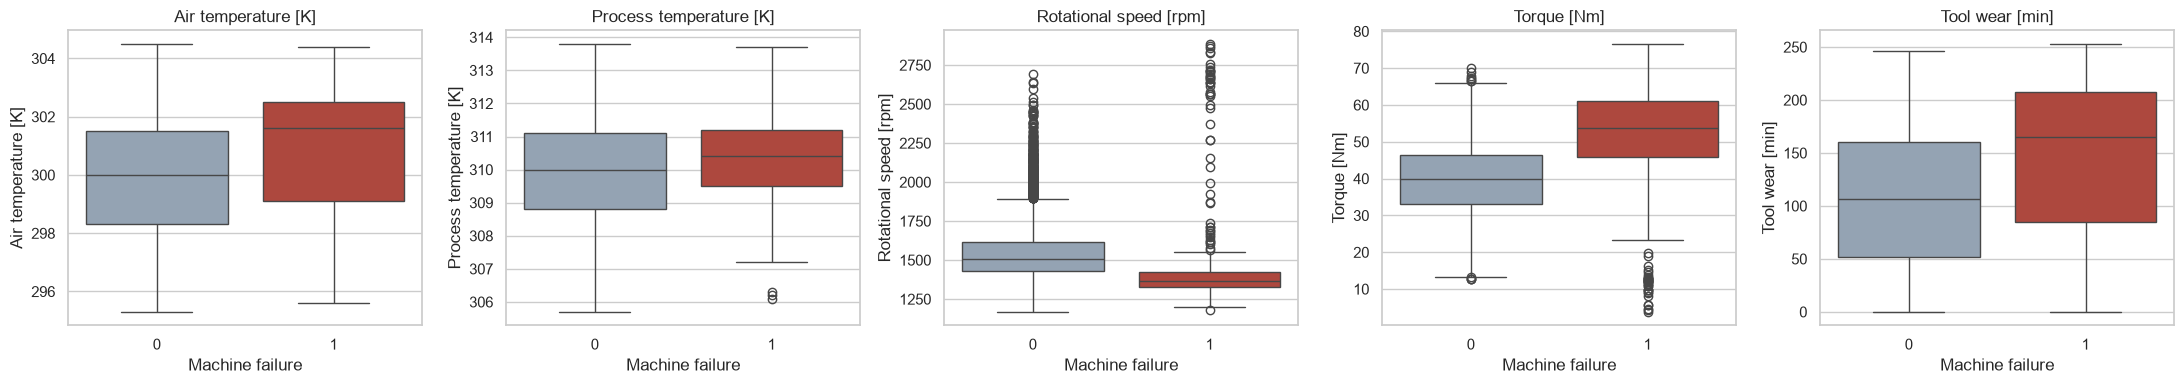

In [27]:
fig, axes = plt.subplots(1, len(FEATURES), figsize=(22, 4))
for ax, feature in zip(axes, FEATURES):
    sns.boxplot(data=df, x=TARGET, y=feature, hue=TARGET, palette=["#8fa3b8", "#c0392b"],
                legend=False, ax=ax)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

> **Conclusión:** el **par**, la **velocidad** y el **desgaste de herramienta** separan en parte las
> filas con fallo; las **temperaturas**, por sí solas, casi no. Pero que una variable no separe sola
> no significa que no sirva: algunos fallos dependen de una **combinación** de variables (ver el
> punto 7).
>
> **Los valores extremos de velocidad no se eliminan.** En mantenimiento, los extremos son
> precisamente la señal: esas velocidades forman parte de la zona de fallo por potencia. Un outlier
> solo se descarta si es un error de medida, no por ser poco frecuente.

## 5. Tipo de producto

`Type`: L (calidad baja), M (media) y H (alta). ¿Cambia la tasa de fallos?

In [28]:
by_type = df.groupby("Type")[TARGET].agg(filas="count", fallos="sum", tasa_fallo="mean")
by_type["tasa_fallo"] = by_type["tasa_fallo"].round(4)
by_type.loc[["L", "M", "H"]]

,filas,fallos,tasa_fallo
Type,,,
L,6000,235,0.0392
M,2997,83,0.0277
H,1003,21,0.0209


> **Conclusión:** los productos de calidad baja (**L**) fallan algo más que los de media y alta,
> aunque la diferencia es moderada. Aun así, `Type` es útil **combinada** con otras variables: en
> AI4I, el umbral de sobreesfuerzo (OSF) depende del tipo de producto.
>
> **Decisión:** `Type` entra en el modelo codificada de forma ordinal (L=0, M=1, H=2). En el nodo,
> el tipo será un dato fijo de la configuración de cada máquina.

## 6. Correlaciones

Fíjate en dos parejas: las dos temperaturas, y la velocidad con el par.

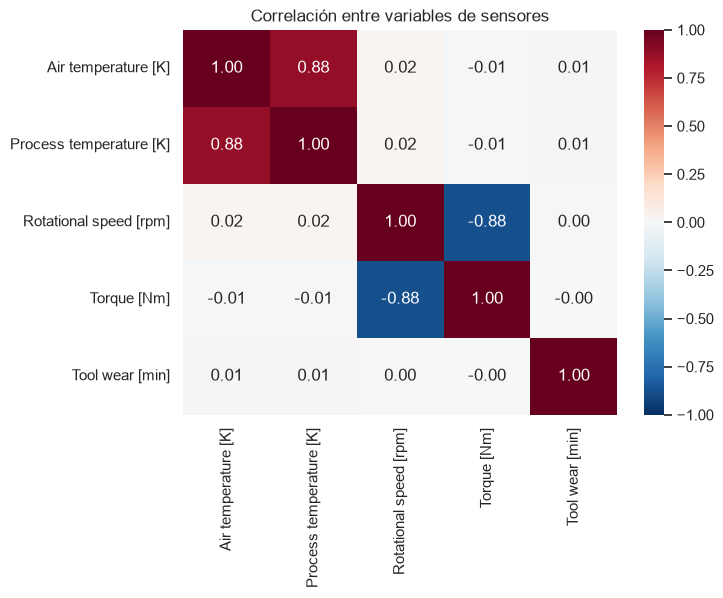

In [29]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlación entre variables de sensores")
plt.show()

> **Conclusión:** dos parejas muy correlacionadas: las **dos temperaturas** (≈ 0,88) y la
> **velocidad con el par** (≈ −0,88).
>
> Correlación **no** significa redundancia: el fallo por calor depende de la **diferencia** entre
> temperaturas, y el de potencia, del **producto** de velocidad y par. Eliminar una variable de cada
> pareja perdería justo esa información. Además, los modelos de árboles toleran bien las variables
> correlacionadas.
>
> **A tener en cuenta en la explicabilidad:** SHAP **reparte el mérito** entre variables
> correlacionadas, así que su importancia individual debe interpretarse con cuidado.

## 7. Ingeniería de variables

Variables que reflejan la **física** de cada modo de fallo:

| Variable | Fórmula | Modo de fallo relacionado |
|---|---|---|
| `temp_diff_k` | temperatura de proceso − temperatura del aire | HDF (el calor no se disipa) |
| `power_w` | par × rpm × 2π / 60 | PWF (potencia fuera de rango) |
| `strain` | desgaste × par | OSF (sobreesfuerzo) |

> Estas transformaciones se moverán a `src/maintenance/ml/features.py`, para usar
> **exactamente el mismo código** al entrenar y al predecir en el nodo.

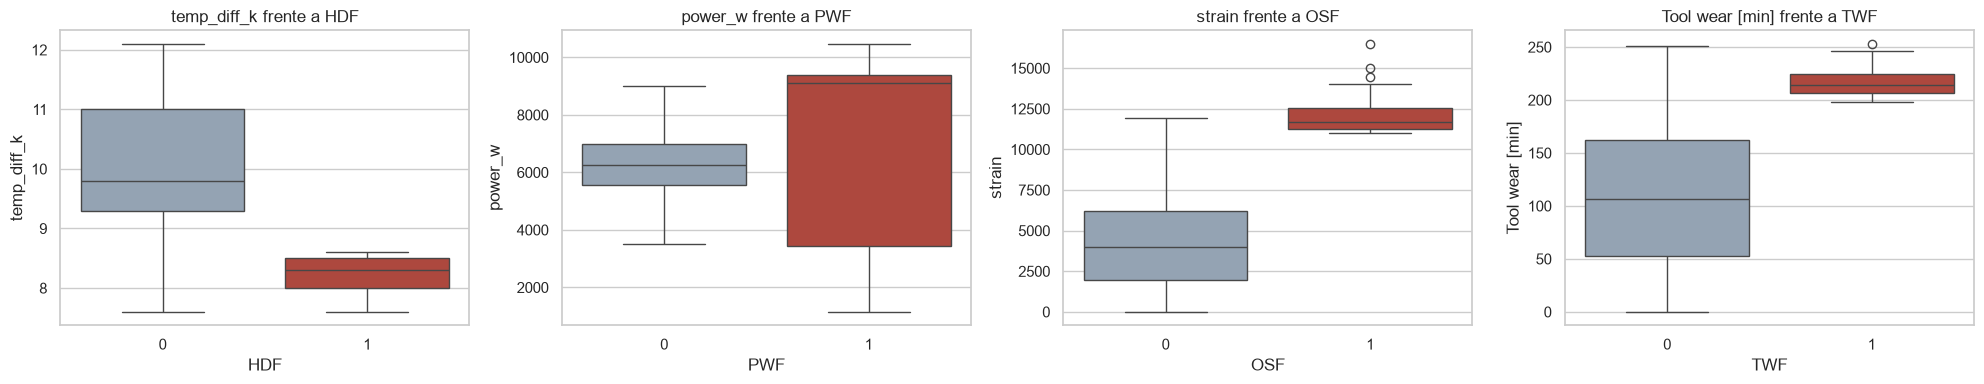

In [30]:
eng = df.copy()
eng["temp_diff_k"] = eng["Process temperature [K]"] - eng["Air temperature [K]"]
eng["power_w"] = eng["Torque [Nm]"] * eng["Rotational speed [rpm]"] * 2 * np.pi / 60
eng["strain"] = eng["Tool wear [min]"] * eng["Torque [Nm]"]

pairs = [
    ("temp_diff_k", "HDF"),
    ("power_w", "PWF"),
    ("strain", "OSF"),
    ("Tool wear [min]", "TWF"),
]
fig, axes = plt.subplots(1, len(pairs), figsize=(20, 4))
for ax, (feature, mode) in zip(axes, pairs):
    sns.boxplot(data=eng, x=mode, y=feature, hue=mode, palette=["#8fa3b8", "#c0392b"],
                legend=False, ax=ax)
    ax.set_title(f"{feature} frente a {mode}")
plt.tight_layout()
plt.show()

### Una mirada más fina: dos variables a la vez

Algunos fallos no dependen de una variable sola, sino de una **combinación**.

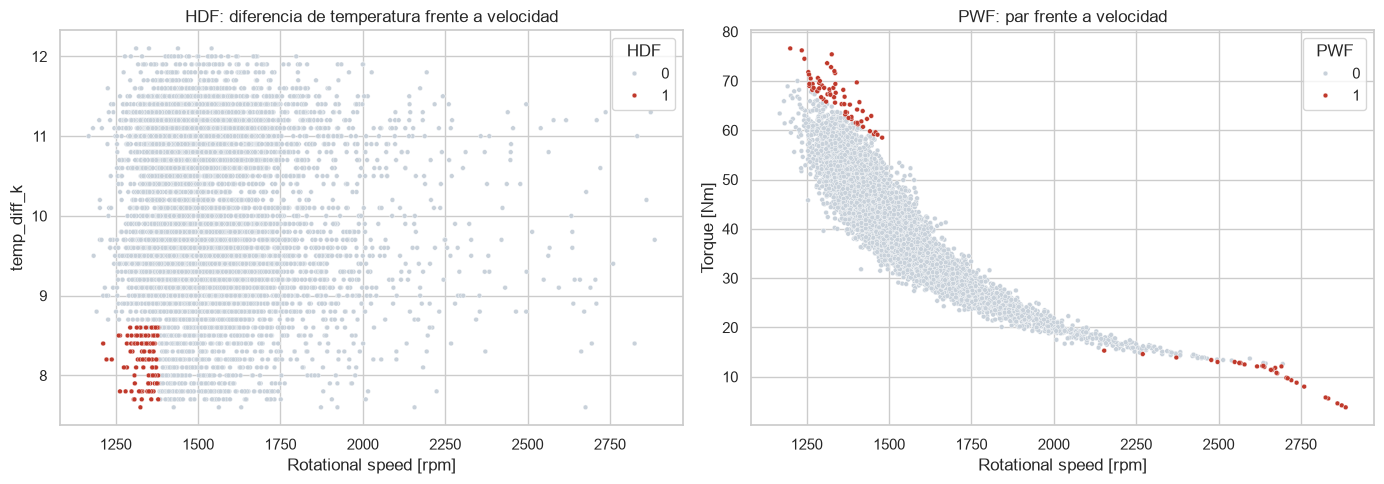

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=eng.sort_values("HDF"), x="Rotational speed [rpm]", y="temp_diff_k",
                hue="HDF", palette=["#c8d1da", "#c0392b"], s=12, ax=axes[0])
axes[0].set_title("HDF: diferencia de temperatura frente a velocidad")

sns.scatterplot(data=eng.sort_values("PWF"), x="Rotational speed [rpm]", y="Torque [Nm]",
                hue="PWF", palette=["#c8d1da", "#c0392b"], s=12, ax=axes[1])
axes[1].set_title("PWF: par frente a velocidad")

plt.tight_layout()
plt.show()

> **Conclusión:** las variables derivadas separan mucho mejor sus modos de fallo que las originales.
> La diferencia de temperaturas, sola, todavía se solapa con HDF; los diagramas de dispersión
> explican por qué:
>
> - **HDF** se concentra en una **esquina**: diferencia de temperatura baja **y** velocidad baja a
>   la vez. Es una región definida por dos umbrales, justo lo que un árbol aprende con dos cortes.
> - **PWF** aparece cuando la potencia es **demasiado baja o demasiado alta**: en el plano
>   velocidad-par son dos zonas curvas a ambos lados de una banda, que **ninguna recta separa**.
>   Con la variable `power_w`, en cambio, bastan dos umbrales.
>
> **Por qué árboles y no KNN:** KNN tendría que guardar todo el conjunto de entrenamiento y comparar
> cada lectura con él, algo caro en un nodo Edge con 0,5 CPU y 256 MB, y además exige escalar las
> variables. Los árboles predicen con unos pocos cortes por árbol, en microsegundos.

### Vista previa del conjunto de entrada del modelo

Las transformaciones se trasladarán a `src/maintenance/ml/features.py`, y tanto el entrenamiento
como el nodo usarán **ese mismo módulo**, para evitar el *training-serving skew*.

In [32]:
TYPE_CODES = {"L": 0, "M": 1, "H": 2}

model_input = pd.DataFrame({
    "type_code": df["Type"].map(TYPE_CODES),
    "air_temperature_k": df["Air temperature [K]"],
    "process_temperature_k": df["Process temperature [K]"],
    "rotational_speed_rpm": df["Rotational speed [rpm]"],
    "torque_nm": df["Torque [Nm]"],
    "tool_wear_min": df["Tool wear [min]"],
    "temp_diff_k": eng["temp_diff_k"],
    "power_w": eng["power_w"],
    "strain": eng["strain"],
})
model_input.head()

,type_code,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min,temp_diff_k,power_w,strain
0,1,298.1,308.6,1551,42.8,0,10.5,6951.590560,0.0
1,0,298.2,308.7,1408,46.3,3,10.5,6826.722724,138.9
2,0,298.1,308.5,1498,49.4,5,10.4,7749.387543,247.0
3,0,298.2,308.6,1433,39.5,7,10.4,5927.504659,276.5
4,0,298.2,308.7,1408,40.0,9,10.5,5897.816608,360.0


## Decisiones para el entrenamiento

| Decisión | Elección | Motivo |
|---|---|---|
| **Etiqueta** | Fallos de proceso: HDF, PWF u OSF | RNF es aleatorio; hay filas de `Machine failure` contradictorias; TWF no tiene señal en las variables |
| **Desgaste de herramienta (TWF)** | Regla de mantenimiento preventivo en el dominio del nodo | Se gestiona sustituyendo la herramienta por desgaste, como en planta: reglas para lo determinista, ML para lo complejo |
| **Variables de entrada** | Las 5 de sensores, `type_code` y las derivadas `temp_diff_k`, `power_w` y `strain` | Reflejan la física de cada modo de fallo |
| **Excluidas** | `UDI`, `Product ID` y las columnas de modos | Identificadores; las columnas de modos son la propia etiqueta (fuga de datos) |
| **Desequilibrio** | División estratificada y pesos de clase en LightGBM | Mantener la proporción de fallos y compensar la clase minoritaria |
| **Modelo** | LightGBM (gradient boosting de árboles) | Fronteras por umbrales, ligero en el Edge y con TreeSHAP nativo |
| **Métricas** | PR-AUC y recall en el umbral elegido | La accuracy engaña con un 3,4 % de fallos; un fallo no detectado cuesta más que una falsa alarma |

### Resultado del entrenamiento (partición de prueba)

| Métrica | Etiqueta con TWF | Etiqueta final (HDF, PWF, OSF) |
|---|---|---|
| PR-AUC | 0,927 | **0,984** |
| Precisión | 0,78 | **0,90** |
| Recall | 0,86 | **0,91** |
| Falsas alarmas | 16 | **6** |
| Fallos no detectados | 9 | **5** |

Detalle completo y trazabilidad en `models/failure_model.json`, generado por `scripts/train_model.py`.

### Limitación conocida

AI4I es un dataset **sintético**: sus fallos se generaron con reglas de umbral sobre estas mismas
variables, así que un modelo de árboles obtendrá resultados casi perfectos. Con datos reales de
planta cabe esperar más ruido, y la validación debería ser **temporal** (entrenar con el pasado y
evaluar con el futuro), no con una división aleatoria.